In [238]:
# import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import requests
import logging
from io import StringIO

import import_ipynb 

%matplotlib inline


Cleaned and prepared dataframes in differenet .ipynb files.

**df_google_review_ratings.csv** - Our google review rating dataset.

**df_us_state_city_population.csv** - US state and city population from wikipedia HTML pages.

**df_us_holiday_api.csv** - US holidays year 2025 from api-ninjas.com

**df_us_aqi_api.csv** - US city Air Quality Index from api-ninjas.com

We can run the previous .ipynb files in this Jupyter Notebook file.

%run google_review_ratings.ipynb.ipynb

%run US_state_city_population.ipynb

%run US_aqi_api.ipynb

### Loading cleaned and prepared dataframes

In [239]:
# Loading df_google_review_ratings.csv file.
df_2= 'df_google_review_ratings.csv'

# Catch any exception reading file
try: 
    df_google_review_2 = pd.read_csv(f'{df_2}', index_col=0 ) # first column is the index in the file
except FileNotFoundError: # if file is not not found. 
    print(f"Error: The file '{df_2}' was not found.")

df_google_review_2.head()

,user_id,churches,resorts,beaches,parks,theatres,museums,malls,zoo,restaurants,pubs_bars,local_services,burger_pizza_shops,hotels_other_lodgings,juice_bars,art_galleries,dance_clubs,swimming_pools,gyms,bakeries,beauty_spas,cafes,view_points,monuments,gardens,date,is_weekend,is_holiday,season,city
0,User 1,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.35,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-11-08,True,False,Fall,Santa Monica
1,User 2,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.64,2.33,2.65,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-07-31,False,False,Summer,Chicago
2,User 3,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-06-01,True,False,Summer,Santa Monica
3,User 4,0.0,0.5,3.63,3.63,5.0,2.92,5.0,2.35,2.33,2.64,1.73,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-01-01,False,True,Winter,Chicago
4,User 5,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-07-01,False,False,Summer,Chicago


In [240]:
# Replace "Santa Monica" with "Los Angeles" values.
# we do not have "Santa Monica" in our other api dataset.
df_google_review_2["city"] = df_google_review_2["city"].replace("Santa Monica", "Los Angeles")
df_google_review_2["city"].value_counts()

city
New York       1404
Chicago        1367
Miami          1366
Los Angeles    1319
Name: count, dtype: int64

In [241]:
# Loading df_us_state_city_population.csv file.
df_3= 'df_us_state_city_population.csv'

# Catch any exception reading file
try: 
    df_us_population_3 = pd.read_csv(f'{df_3}', index_col=0 ) # first column is the index in the file
except FileNotFoundError: # if file is not not found. 
    print(f"Error: The file '{df_3}' was not found.")

df_us_population_3.head()

,City,State,City_population_2024,State_population_2024,Base_state_sales_tax
0,New York,New York,8478072,19867248,4%
1,Los Angeles,California,3878704,39431263,7.25%
2,Chicago,Illinois,2721308,12710158,6.25%
3,Houston,Texas,2390125,31290831,6.25%
4,Phoenix,Arizona,1673164,7582384,5.6%


In [242]:
# Loading df_us_holiday_api.csv file.
df_4= 'df_us_holiday_api.csv'

# Catch any exception reading file
try: 
    df_us_holiday_4 = pd.read_csv(f'{df_4}', index_col=0 ) # first column is the index in the file
except FileNotFoundError: # if file is not not found. 
    print(f"Error: The file '{df_4}' was not found.")

df_us_holiday_4.head()

,Holiday_Name,Date,Year,US_Regions,Is_Federal
0,New Year's Day,2025-01-01,2025,All Regions,True
1,"Martin Luther King, Jr. Day",2025-01-20,2025,All Regions,True
2,Presidents Day,2025-02-17,2025,All Regions,True
3,Good Friday,2025-04-18,2025,"CT, DE, HI, IN, KY, LA, NC, ND, NJ, TN",False
4,Memorial Day,2025-05-26,2025,All Regions,True


In [243]:
# Loading df_us_aqi_api.csv file.
df_4_1= "df_us_aqi_api.csv"

# Catch any exception reading file
try: 
    df_us_aqi_4 = pd.read_csv(f'{df_4_1}', index_col=0 ) # first column is the index in the file
except FileNotFoundError: # if file is not not found. 
    print(f"Error: The file '{df_4_1}' was not found.")

df_us_aqi_4.head()

,City,State,Air_Quality_Index
0,New York,New York,52
1,Miami,Florida,144
2,Chicago,California,42
3,Los Angeles,California,134
4,Santa Monica,California,137


### Creating Database and loading all the dataframes into tables

In [244]:
# Creating or connect database

db_name = "term5_db"

try:
    # Create or connect to SQLite database
    conn = sqlite3.connect(db_name)

    # Write dataframes to SQL tables
    df_google_review_2.to_sql("tbl_google_review_2", conn, if_exists="replace", index=False)
    df_us_population_3.to_sql("tbl_us_population_3", conn, if_exists="replace", index=False)
    df_us_holiday_4.to_sql("tbl_us_holiday_4", conn, if_exists="replace", index=False)
    df_us_aqi_4.to_sql("tbl_us_aqi_4", conn, if_exists="replace", index=False)

    print("Successfully created DB and uploaded all tables.\n")

    c = conn.cursor() # defining the cursor

    print("Table Counts:")
    sql_statement = "SELECT count(*) as tbl_count FROM tbl_google_review_2"
    rows = c.execute(sql_statement) # execute the sql statement and return result in tuple

    for i in rows:
        print("tbl_google_review_3 count:",i[0])

    sql_statement = "SELECT count(*) FROM tbl_us_population_3"
    rows = c.execute(sql_statement) # execute the sql statement and return result in tuple

    for i in rows:
        print("tbl_us_population_3 count:",i[0])

    sql_statement = "SELECT count(*) FROM tbl_us_holiday_4"
    rows = c.execute(sql_statement) # execute the sql statement and return result in tuple

    for i in rows:
        print("tbl_us_holiday_4 count:",i[0])

    sql_statement = "SELECT count(*) FROM tbl_us_aqi_4"
    rows = c.execute(sql_statement) # execute the sql statement and return result in tuple

    for i in rows:
        print("tbl_us_aqi_4 count:",i[0])

except Exception as e:
    print("Error:", e)

finally:
    conn.close()
    print("\nConnection closed.")

Successfully created DB and uploaded all tables.

Table Counts:
tbl_google_review_3 count: 5456
tbl_us_population_3 count: 346
tbl_us_holiday_4 count: 13
tbl_us_aqi_4 count: 6

Connection closed.


### Combining all tables into one table

In [245]:
# Merging all tables into one table.
create_table = """
            DROP TABLE IF EXISTS tbl_all;
            CREATE TABLE tbl_all AS
            SELECT 
                g.*, 
                p.State,
                p.City_population_2024,
                p.State_population_2024,
                p.Base_state_sales_tax,
                COALESCE(h.Holiday_Name, 'No_Holiday') AS Holiday_Name,
                CASE 
                    WHEN h.Is_Federal = 1 THEN 'True'
                    ELSE 'False'
                END AS Is_Federal,
                a.Air_Quality_Index as AQI
            FROM tbl_google_review_2 g
            JOIN tbl_us_population_3 p
                ON g.city = p.City
            JOIN tbl_us_aqi_4 a
                ON g.city = a.City 
            LEFT JOIN tbl_us_holiday_4 h
                ON g.date = h.Date
            """
conn = sqlite3.connect("term5_db")
cursor = conn.cursor()

try:
    conn = sqlite3.connect("term5_db")
    cursor = conn.cursor()
    cursor.executescript(create_table)
    print("Combined table \"tbl_all\" is a created.")
    
    conn.commit()
    
except Exception as e:
    print("Error:", e)
finally:
    conn.close()
    print("\nConnection closed.")

Combined table "tbl_all" is a created.

Connection closed.


### Get all tables data into a dataframe

In [246]:
try:
    conn = sqlite3.connect("term5_db")

    # Read ALL rows into a pandas DataFrame
    df_all = pd.read_sql_query("SELECT * FROM tbl_all", conn)

finally:
    conn.close()
    
pd.set_option('display.max_columns', 50)
df_all.head()

,user_id,churches,resorts,beaches,parks,theatres,museums,malls,zoo,restaurants,pubs_bars,local_services,burger_pizza_shops,hotels_other_lodgings,juice_bars,art_galleries,dance_clubs,swimming_pools,gyms,bakeries,beauty_spas,cafes,view_points,monuments,gardens,date,is_weekend,is_holiday,season,city,State,City_population_2024,State_population_2024,Base_state_sales_tax,Holiday_Name,Is_Federal,AQI
0,User 1,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.35,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-11-08,1,0,Fall,Los Angeles,California,3878704,39431263,7.25%,No_Holiday,False,134
1,User 2,0.0,0.0,3.63,3.65,5.0,2.92,5.0,2.64,2.33,2.65,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-07-31,0,0,Summer,Chicago,Illinois,2721308,12710158,6.25%,No_Holiday,False,42
2,User 3,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-06-01,1,0,Summer,Los Angeles,California,3878704,39431263,7.25%,No_Holiday,False,134
3,User 4,0.0,0.5,3.63,3.63,5.0,2.92,5.0,2.35,2.33,2.64,1.73,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-01-01,0,1,Winter,Chicago,Illinois,2721308,12710158,6.25%,New Year's Day,True,42
4,User 5,0.0,0.0,3.63,3.63,5.0,2.92,5.0,2.64,2.33,2.64,1.70,1.69,1.7,1.72,1.74,0.59,0.5,0.0,0.5,0.0,0.0,0.0,0.0,0.0,2025-07-01,0,0,Summer,Chicago,Illinois,2721308,12710158,6.25%,No_Holiday,False,42


### Average rating of places by city on non holidays

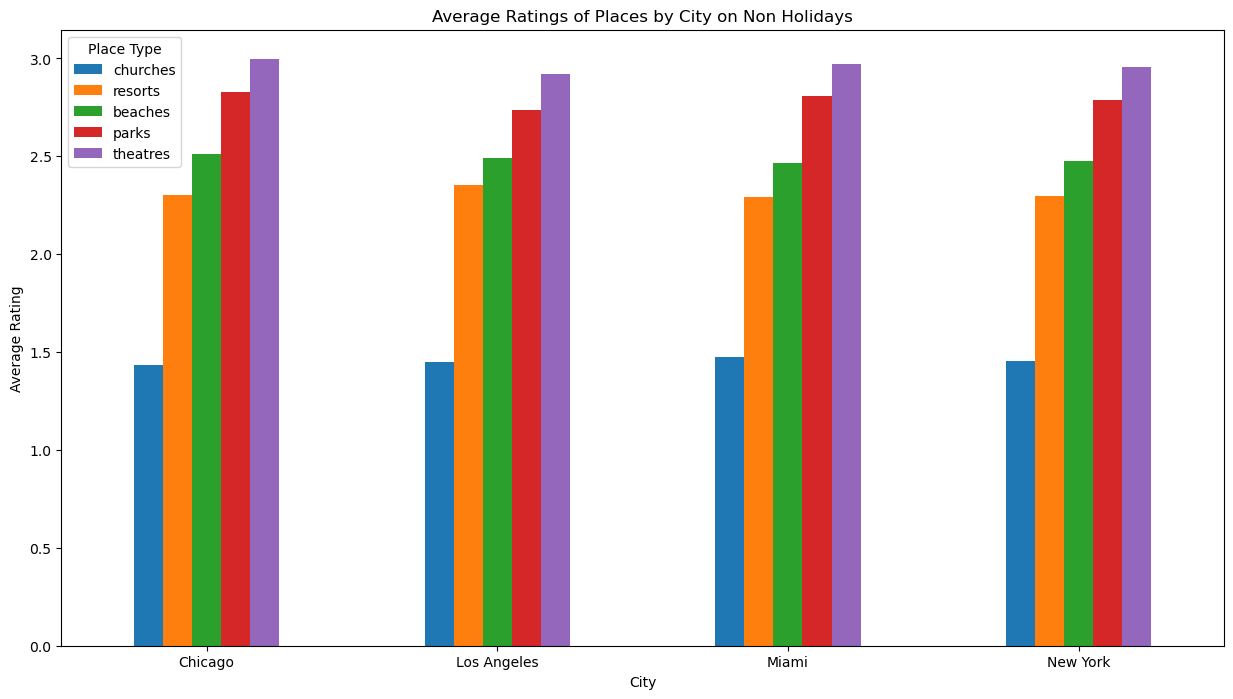

In [247]:
df_non_holiday = df_all[df_all['is_holiday'] == False] # get non holidays reviews

places_cols = ['churches', 'resorts', 'beaches', 'parks', 'theatres']
avg_places_city = df_non_holiday.groupby('city')[places_cols].mean() # group by city and calcualte average reviews

avg_places_city.plot(kind='bar', figsize=(15,8))
plt.title('Average Ratings of Places by City on Non Holidays')
plt.ylabel('Average Rating')
plt.xlabel('City')
plt.xticks(rotation=0)
plt.legend(title='Place Type')
plt.show()

### Total food places reviews by season

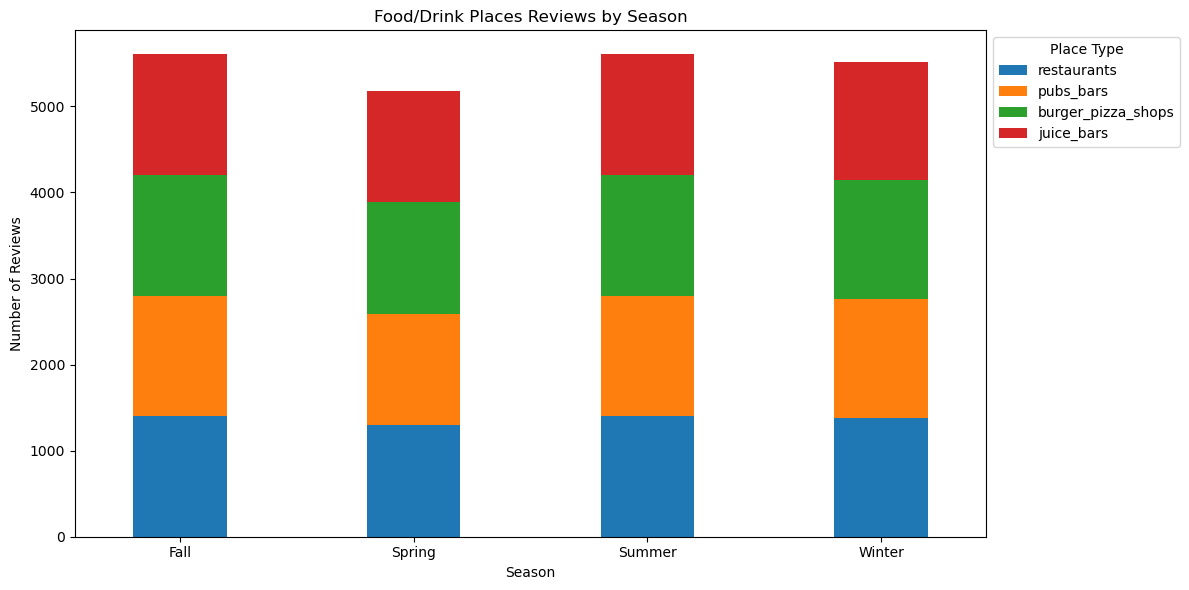

In [252]:
# reviews count by season
season_food = df_all.groupby('season')[['restaurants', 'pubs_bars','burger_pizza_shops','juice_bars']].count()

# Plot stacked bar chart
season_food.plot(kind='bar', width = 0.4, stacked=True, figsize=(12,6))

plt.title('Food/Drink Places Reviews by Season')
plt.xlabel('Season')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=0)
# Move legend outside the plot
plt.legend(title='Place Type', loc='upper left', bbox_to_anchor=(1,1))
plt.tight_layout()  # Adjust layout to fit legend
plt.show()

### Total Reviews per Month

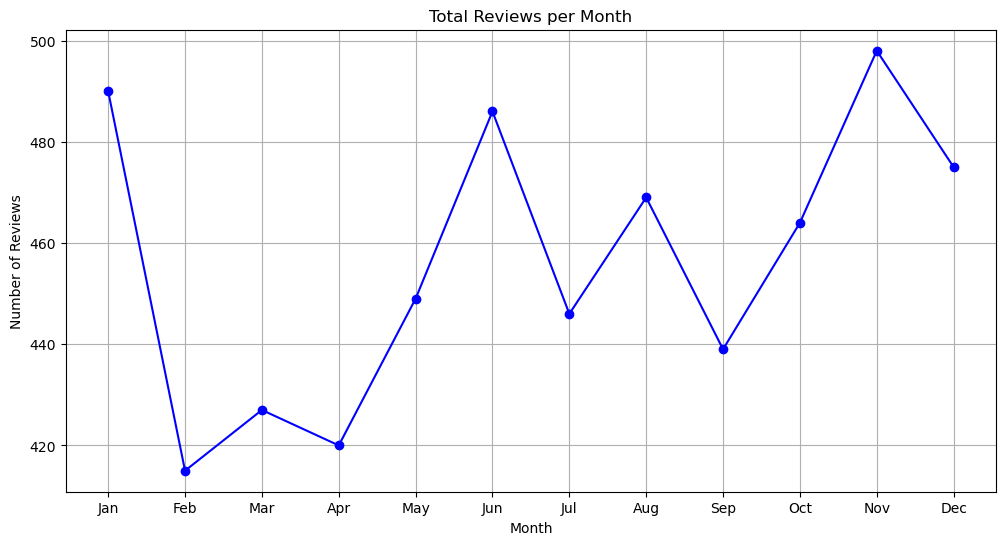

In [249]:
# Converting "date" to datetime
df_all['date'] = pd.to_datetime(df_all['date'])

# Extracting month
df_all['month'] = df_all['date'].dt.strftime('%b')  # 'Jan', 'Feb', etc.

# Group by month and count reviews
reviews_per_month = df_all.groupby('month')['user_id'].count()

# month order
month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
reviews_per_month = reviews_per_month.reindex(month_order)

# Plot line chart
plt.figure(figsize=(12,6))
plt.plot(reviews_per_month.index, reviews_per_month.values, marker='o', linestyle='-', color='b')
plt.title('Total Reviews per Month')
plt.xlabel('Month')
plt.ylabel('Number of Reviews')
plt.grid(True)
plt.show()


### Weekend vs Weekday and Holiday vs Non-Holiday Reviews

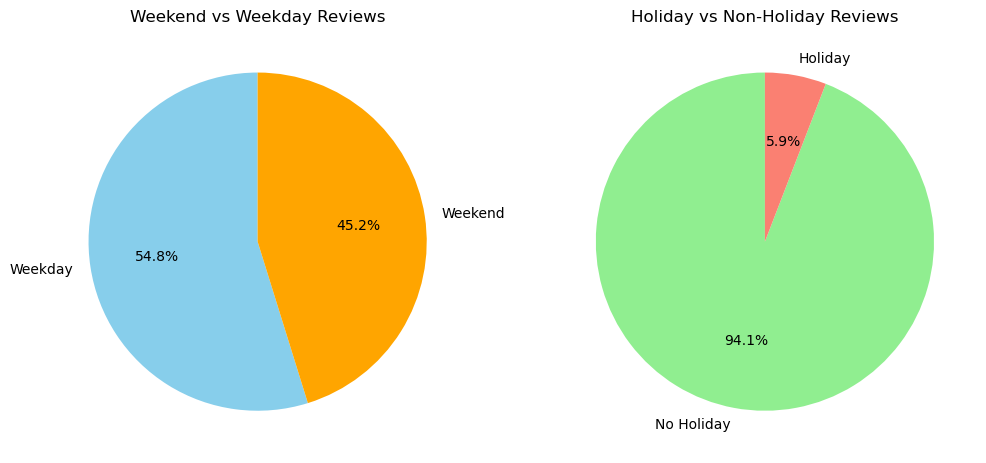

In [250]:
# Aggregate counts across all seasons
weekend_counts = df_all['is_weekend'].value_counts() # by weekend counts 
holiday_counts = df_all['is_holiday'].value_counts() # by holiday counts

# Labels
weekend_labels = ['Weekday', 'Weekend']
holiday_labels = ['No Holiday', 'Holiday']

# figure with 2 subplots
fig, axes = plt.subplots(1, 2, figsize=(12,6))

# Pie chart for weekend vs weekday
axes[0].pie(weekend_counts, labels=weekend_labels, autopct='%1.1f%%', startangle=90, colors=['skyblue', 'orange'])
axes[0].set_title('Weekend vs Weekday Reviews')

# Pie chart for holiday vs non-holiday
axes[1].pie(holiday_counts, labels=holiday_labels, autopct='%1.1f%%', startangle=90, colors=['lightgreen', 'salmon'])
axes[1].set_title('Holiday vs Non-Holiday Reviews')

plt.show()


### Number of Reviews by City and Air Quality Index

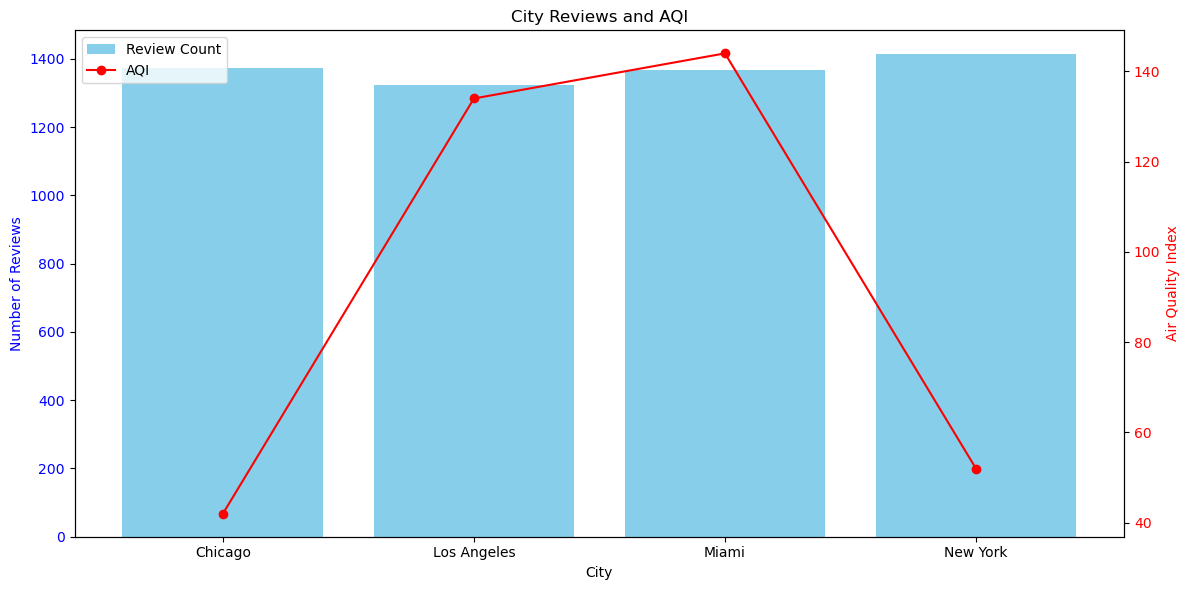

In [251]:
# Aggregate data by city
city_stats = df_all.groupby('city').agg({
    'AQI': 'mean', # AQI Average
    'user_id': 'count',  # number of reviews
}).reset_index()

fig, ax1 = plt.subplots(figsize=(12,6))

# Bar chart for review count
bars = ax1.bar(city_stats['city'], city_stats['user_id'], color='skyblue', label='Review Count')
ax1.set_xlabel('City')
ax1.set_ylabel('Number of Reviews', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

# Secondary y-axis for AQI
ax2 = ax1.twinx()
ax2.plot(city_stats['city'], city_stats['AQI'], color='red', marker='o', label='AQI')
ax2.set_ylabel('Air Quality Index', color='red')
ax2.tick_params(axis='y', labelcolor='red')

# Combine legends
lines_labels = [ax1.get_legend_handles_labels(), ax2.get_legend_handles_labels()]
lines, labels = [sum(lol, []) for lol in zip(*lines_labels)]
ax1.legend(lines, labels, loc='upper left')
plt.title('City Reviews and AQI')
plt.tight_layout()  # Adjust layout to fit legend
plt.show()


### Summary
We combined multiple data sources, including Google review activity, U.S. population statistics, holiday calendars, and air-quality data. By merging these four tables into a single master dataset, it becomes possible to explore how environmental conditions, seasonal variations, holidays, and urban characteristics influence user activity and review behavior across major U.S. cities.


### Ethical Considerations

The ethical considerations primarily involve ensuring data privacy and maintaining integrity in downloading the Google review rating dataset, fetching and handling the API data, and using the population data from Wikipedia for project work. All three data sources are publicly available. 

  We maintained transparency by documenting all cleaning steps, loading data into tables, merging into one table, ensuring reproducibility, and avoiding transformations that could distort the purpose of the analysis.